# Clustering packets of WPT using k-means method
Here we use entropy, kurtosis and crest for k-means clustering and thresholding. The test data are generated by solving GA bubble model.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:
%matplotlib inline
sys.path.append("..")

import matplotlib.pyplot as plt
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

import numpy as np
import wavelet_transform.utils.training_data as train
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.wpt.inverse_transform as inv
from wavelet_transform.utils.extensions import fft, trim_data
from wavelet_transform.utils.machine_learning import fit_and_evaluate, train_k_means, assess_parameter
import wavelet_transform.utils.kmeans_results as results
from wavelet_transform.utils.preprocessing import preprocess
from wavelet_transform.utils.bubbledynamics import BubbleDynamics as BD

### Parameters

Specify parameters for synthetic data and wavelet transform

pac = 10, r_init = 1e-6 for transient

pac = 1, r_init = 10e-6 for stable

In [3]:
pac = 1e6  # the amplitude of the sine wave in Pa
frequency = 2 * 1e6  # insonation frequency (Hz)
R_init = 10e-6  # initial bubble radius in meters
period = 1 / frequency # the period of the acoustic wave at the fundamental frequency 
n_cycles = 30  # no. of cycles of the sine wave

parameters = {
    "time_delay": 0 * period,  # time delay, t1
    "pulse_width": n_cycles * period,  # pulse width, W = 1 / Q
    "phase_initial": 0 * period,  # tau
    "phase_shift": 0 * np.pi / 4,  # phi
    "no_harmonics": 1,   # k
    "Rdot_init": 0,  # initial bubble's wall velocity in m/s
}

r_measure = 1e-3 # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time

In [4]:
# Set sampling rate and noise std
sampling_rate = 50e6
signal2noise = 30

In [5]:
# Parameters for the wavelet transform
wavelet = "db10"
levels = 10  # set to None to use max-level transform
mode = "symmetric"
use_min_entropy = True
min_level = 4
freq_threshold = 15e6  / (sampling_rate / 2)  # the nodes with norm_freq_range above this threshold will not be kept

### Generating acoustic emission data by solving Gilmore-Akulichev model

Generate the acoustic emission data and add measurement noise (assuming additive white Gaussian noise). Plot the data with its FFT. 

In [6]:
# BUBBLE DYNAMICS DATA
data, t_plot = train.get_data(
    R_init, frequency, pac, sampling_rate, n_cycles=n_cycles, r_measure=r_measure,
    return_time=True, **parameters
)

# Add noise
data = train.add_noise(data, signal2noise, display_std_noise=True)

data, t_plot = trim_data(data, t_plot, (0.5e-6, 15e-6), return_time=True)

std_noise: 0.010676147225226345


In [7]:
# Normalise
data_processed = preprocess(data, window=False)

In [8]:
# Plot generated data
fft_lim = 5
fft_data, freq = fft(data_processed, sampling_rate, frequency)
# plot sound wave and fft
fig = make_subplots(rows=3, cols=1)
fig.add_trace( go.Scatter(x=t_plot, y=data_processed, mode='lines',name='data'),
              row=1,col=1)
fig.add_trace( go.Scatter(x=freq,y=np.log10(np.abs(fft_data)),mode='lines',name='fft - amp'),
              row=2,col=1)
fig.add_trace( go.Scatter(x=freq, y=np.angle(fft_data, deg=True),mode='lines', name = 'fft - phase'),
              row=3,col=1)

fig.update_layout(height=600, width=800,
                  xaxis1 = dict(title='Time [s]'),
                  xaxis2 = dict(title='Freq [f/f_0]', range=[0, fft_lim]),
                  xaxis3 = dict(title='Freq [f/f_0]', range=[0, fft_lim]),
                  yaxis1 = dict(title='Amplitude [DL]'),
                  yaxis2 = dict(title='Amplitude [dB]'),
                  yaxis3 = dict(title='Amplitude [rad]'))
fig.show()

Wavelet transform

In [9]:
wpt_df, tr_obj = train.generate_training_data(
    data_processed, levels, wavelet, mode, 
    include_tr_obj=True, min_entropy=use_min_entropy,
    min_level=min_level, freq_threshold=freq_threshold
)

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

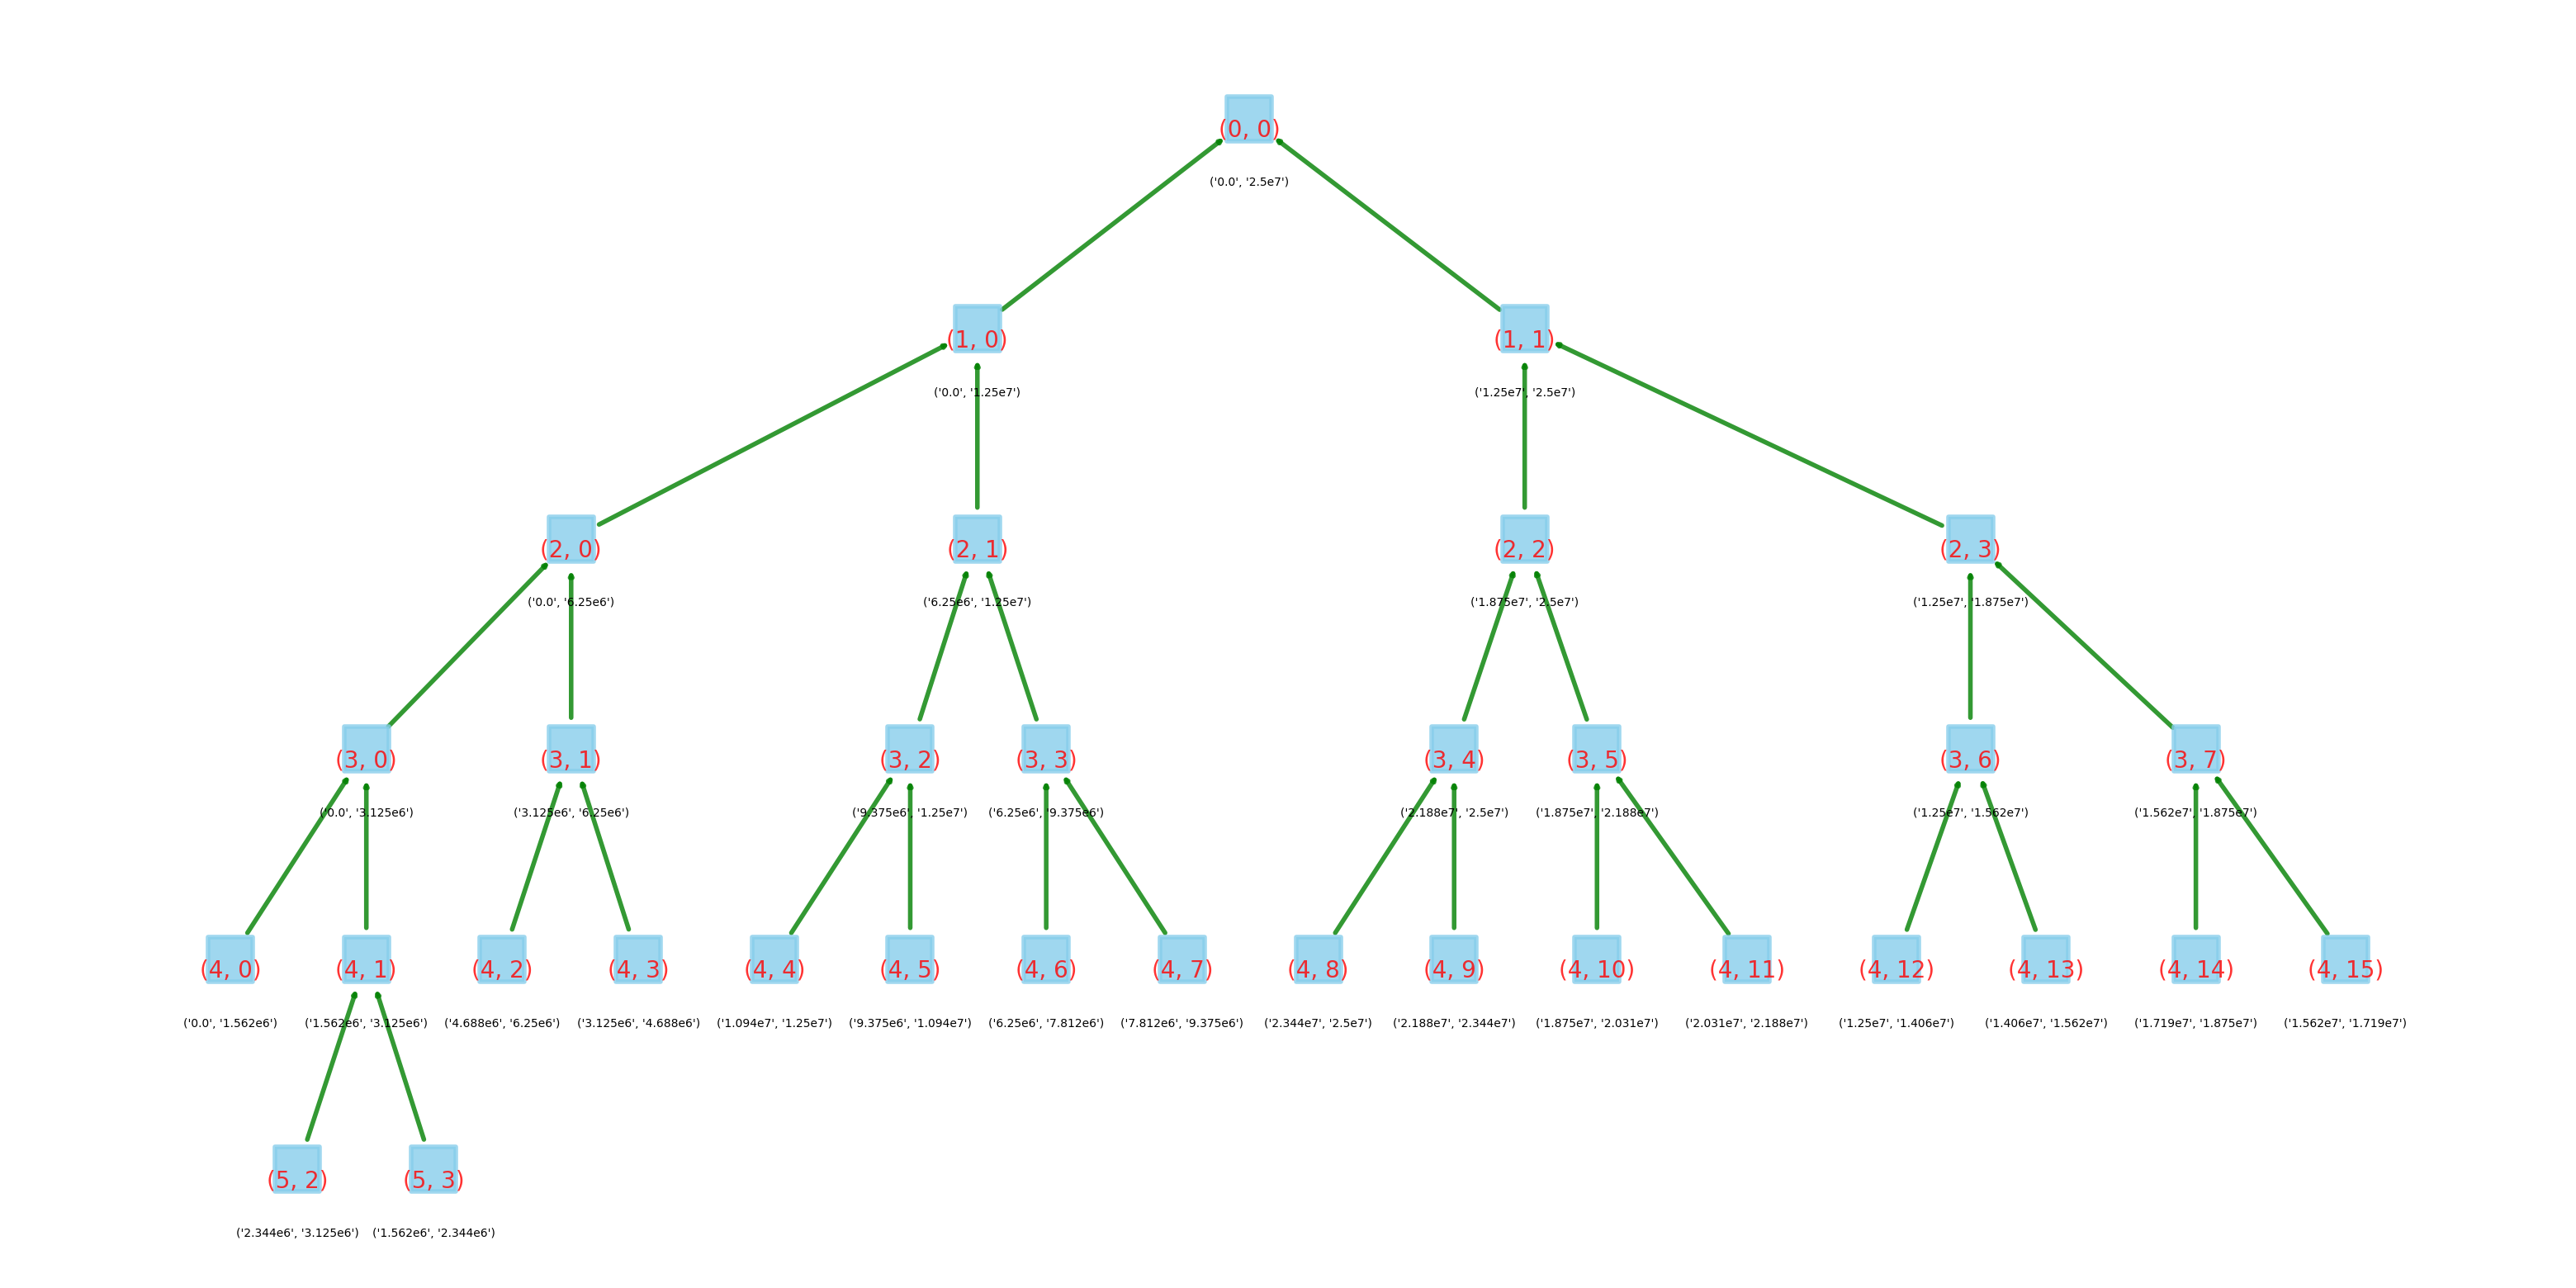

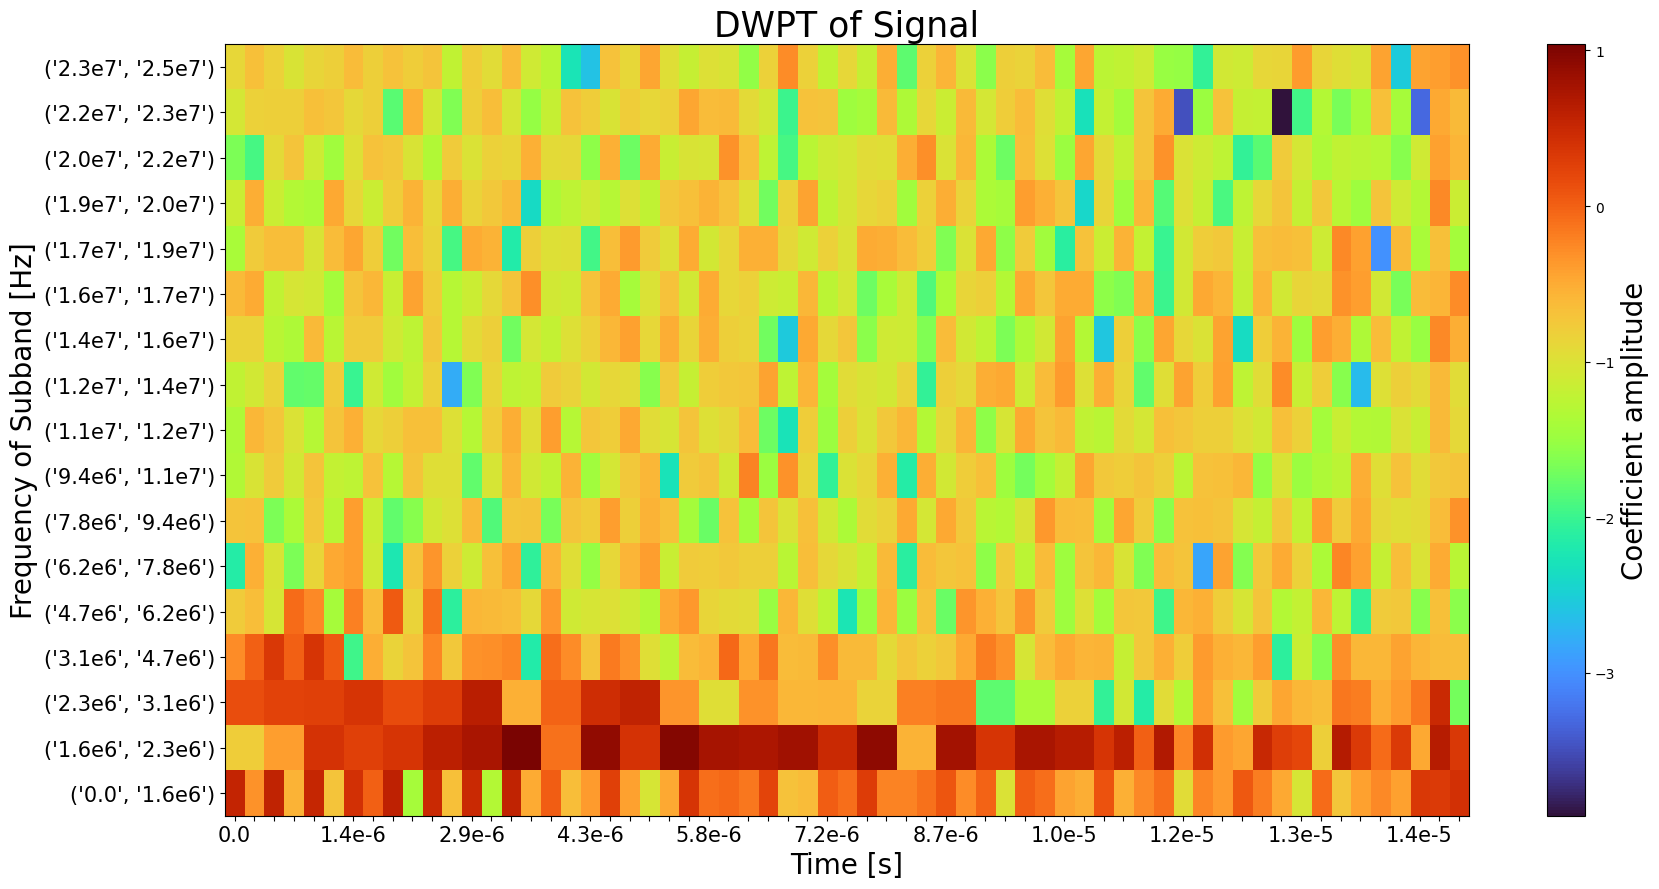

In [10]:
tr_obj.calc_frequencies(sampling_rate)
plot.heisenberg(tr_obj, max(t_plot))

In [ ]:
# wpt_df.plot.bar()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

### K-means without PCA

In [ ]:
# k-means parameters
kmeans_params = {"init": "k-means++",
    "n_init":10,
    "max_iter":100,
    "tol":1e-8,
    "verbose":0,
    "algorithm":"lloyd",
    }

# training data
classifying_metrics = [
    "average energy",
    "kurtosis",
    # "crest factor",
    # "log average energy",
    # "level entropy",
    "spectral entropy",
    # "skewness"
]
# Set to None to select optimal number of clusters by silhouette score
no_clusters = None
use_inverse_metrics = False
if use_inverse_metrics is True:
    inv_tr_obj = inv.InverseTransform(tr_obj)  # Use info from inverse transform object instead
    wpt_df_train = inv_tr_obj.info(leaf_nodes=True)
else:
    wpt_df_train = wpt_df.copy()

In [ ]:
data_train, labels, data_train_normalised, centers, _, kmeans = train_k_means(
    wpt_df_train, classifying_metrics, no_clusters=no_clusters, kmeans_params=kmeans_params
)

### Evaluate k-means using a range of metrics 

see scikit learn documentation https://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html

In [ ]:
# fit_and_evaluate(kmeans, data_train_normalised, labels, name='wpt data', n_runs=100)

Numerical sensitivity analysis

In [ ]:
# parameter_of_interest = "max_iter"
# values = [i for i in range(1, 100, 2)]
# rand_indices = assess_parameter(
#     parameter_of_interest, values, wpt_df_train, 
#     classifying_metrics, no_clusters
# )

# plt.plot(values, rand_indices)
# plt.title(f"Effect of {parameter_of_interest} on clustering algorithm")
# plt.ylabel("Adjusted rand index")
# plt.xlabel(f"{parameter_of_interest.capitalize()}")
# plt.show()

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [ ]:
# data_train_predict_pca, labels_pca, _, centers_pca, scaler, kmeans_pca, pca = train_k_means(
#     wpt_df_train, classifying_metrics, no_clusters=no_clusters, use_pca=True, kmeans_params=kmeans_params
# )

## Save results

In [ ]:
# result_id = f"{R_init}_{frequency}_{pac}"

# # Gather db parameters for storage
# bd_params = {
#     "R_init": R_init,
#     "frequency": frequency,
#     "pac": pac,
# }

# bd_params.update(parameters)

# additional_params = {
#     "raw_data": data,
#     "bd_params": bd_params
# }

# results.save_data(
#     result_id, data_train, tr_obj, centers, labels, 
#     sampling_rate, freq_threshold, **additional_params
# )

# Plotting

### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

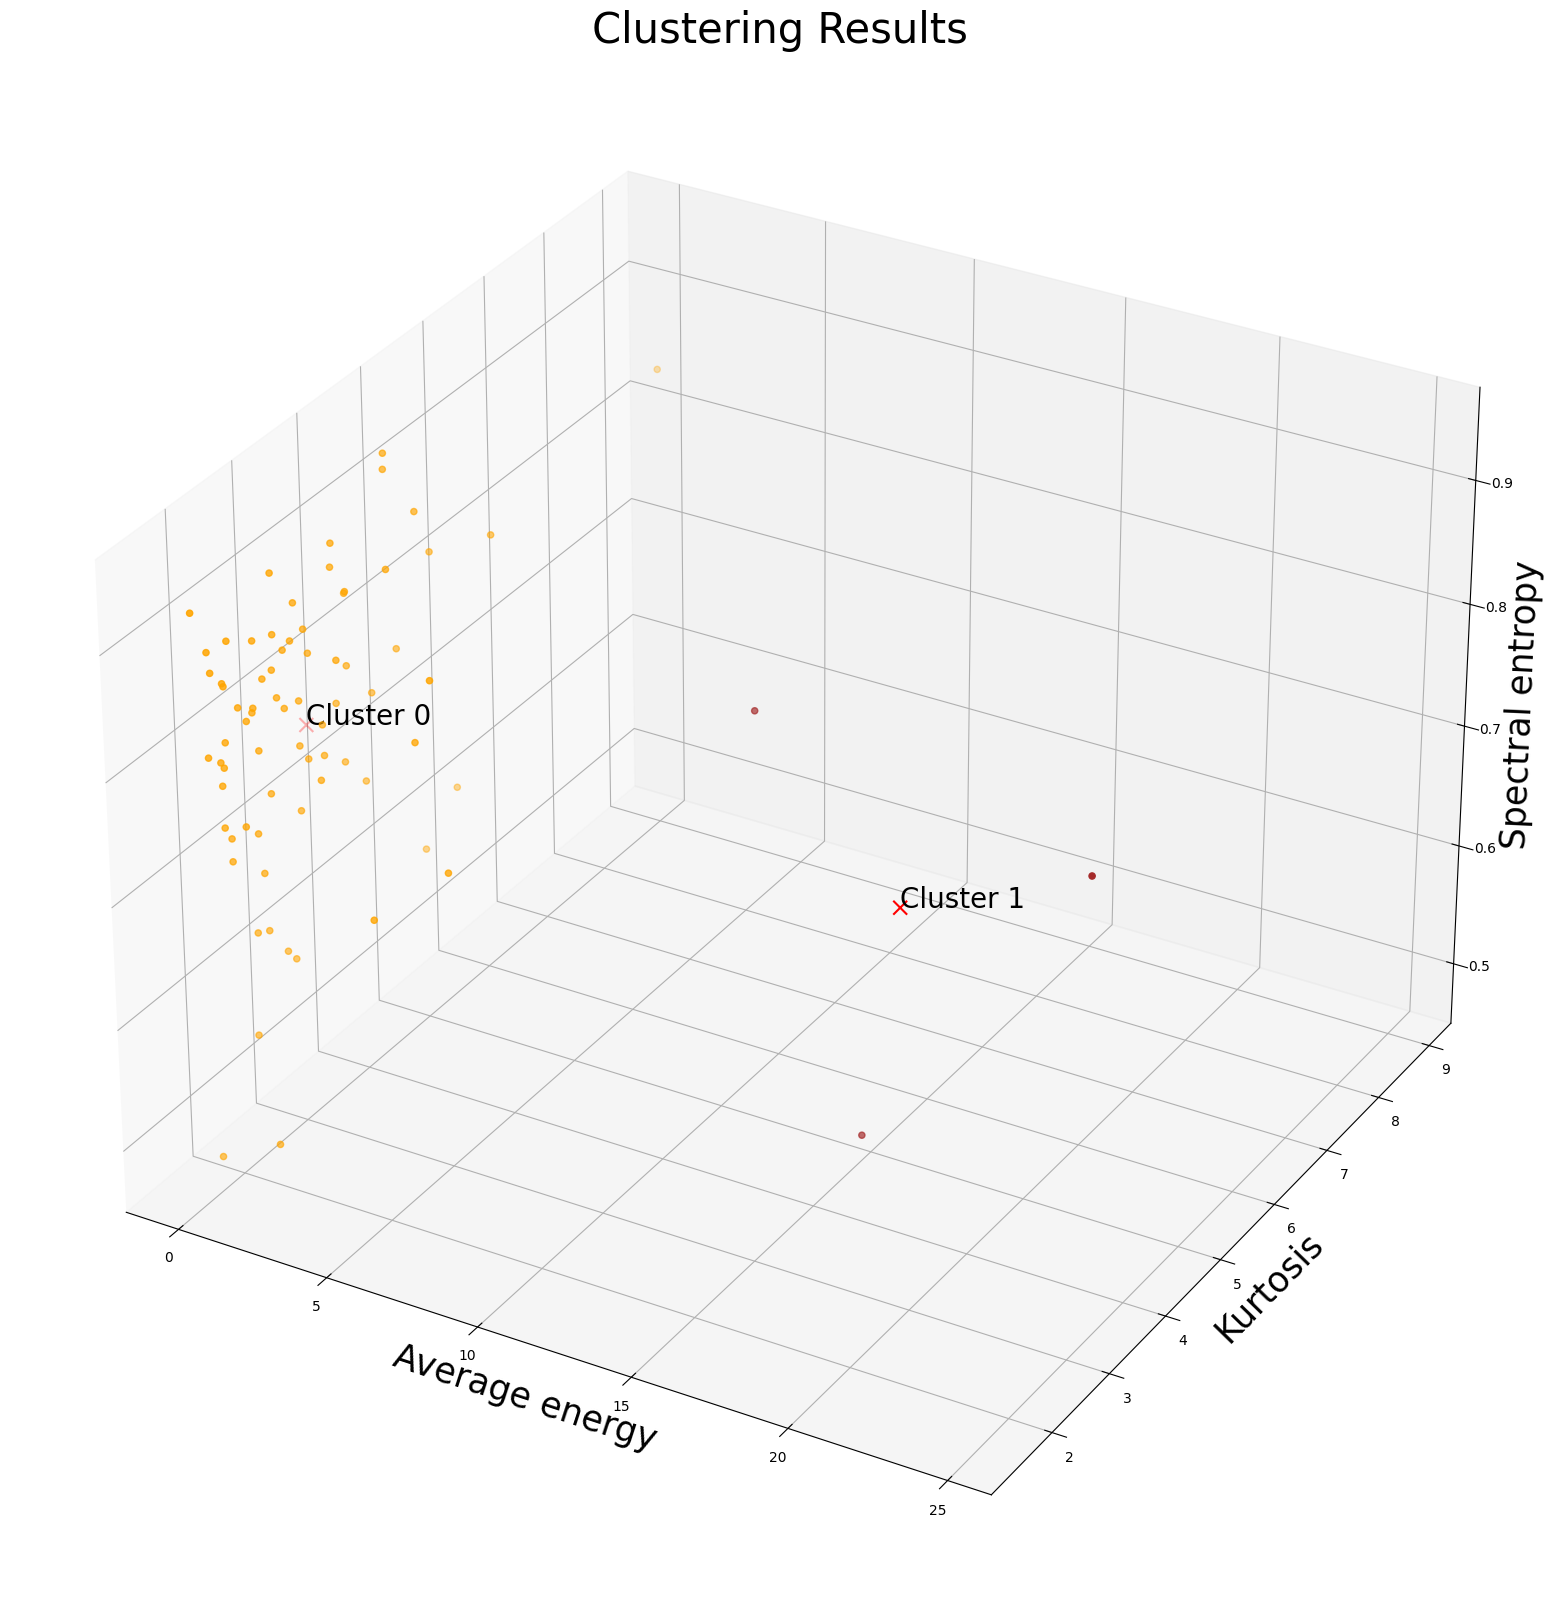

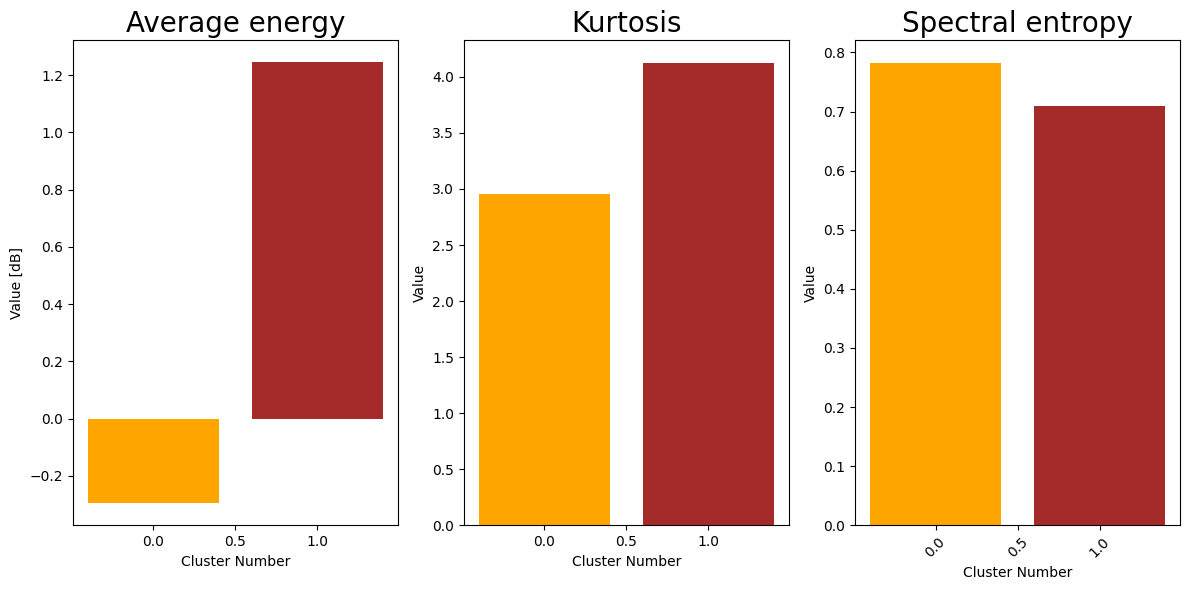

In [ ]:
fig = plot.plot_clustering(data_train, centers, labels)

# Plot centroid metrics
fig = plot.plot_centers(classifying_metrics, centers)

### Results

Plotting the reconstructed waves at each node alongside their assigned group number (non-pca).

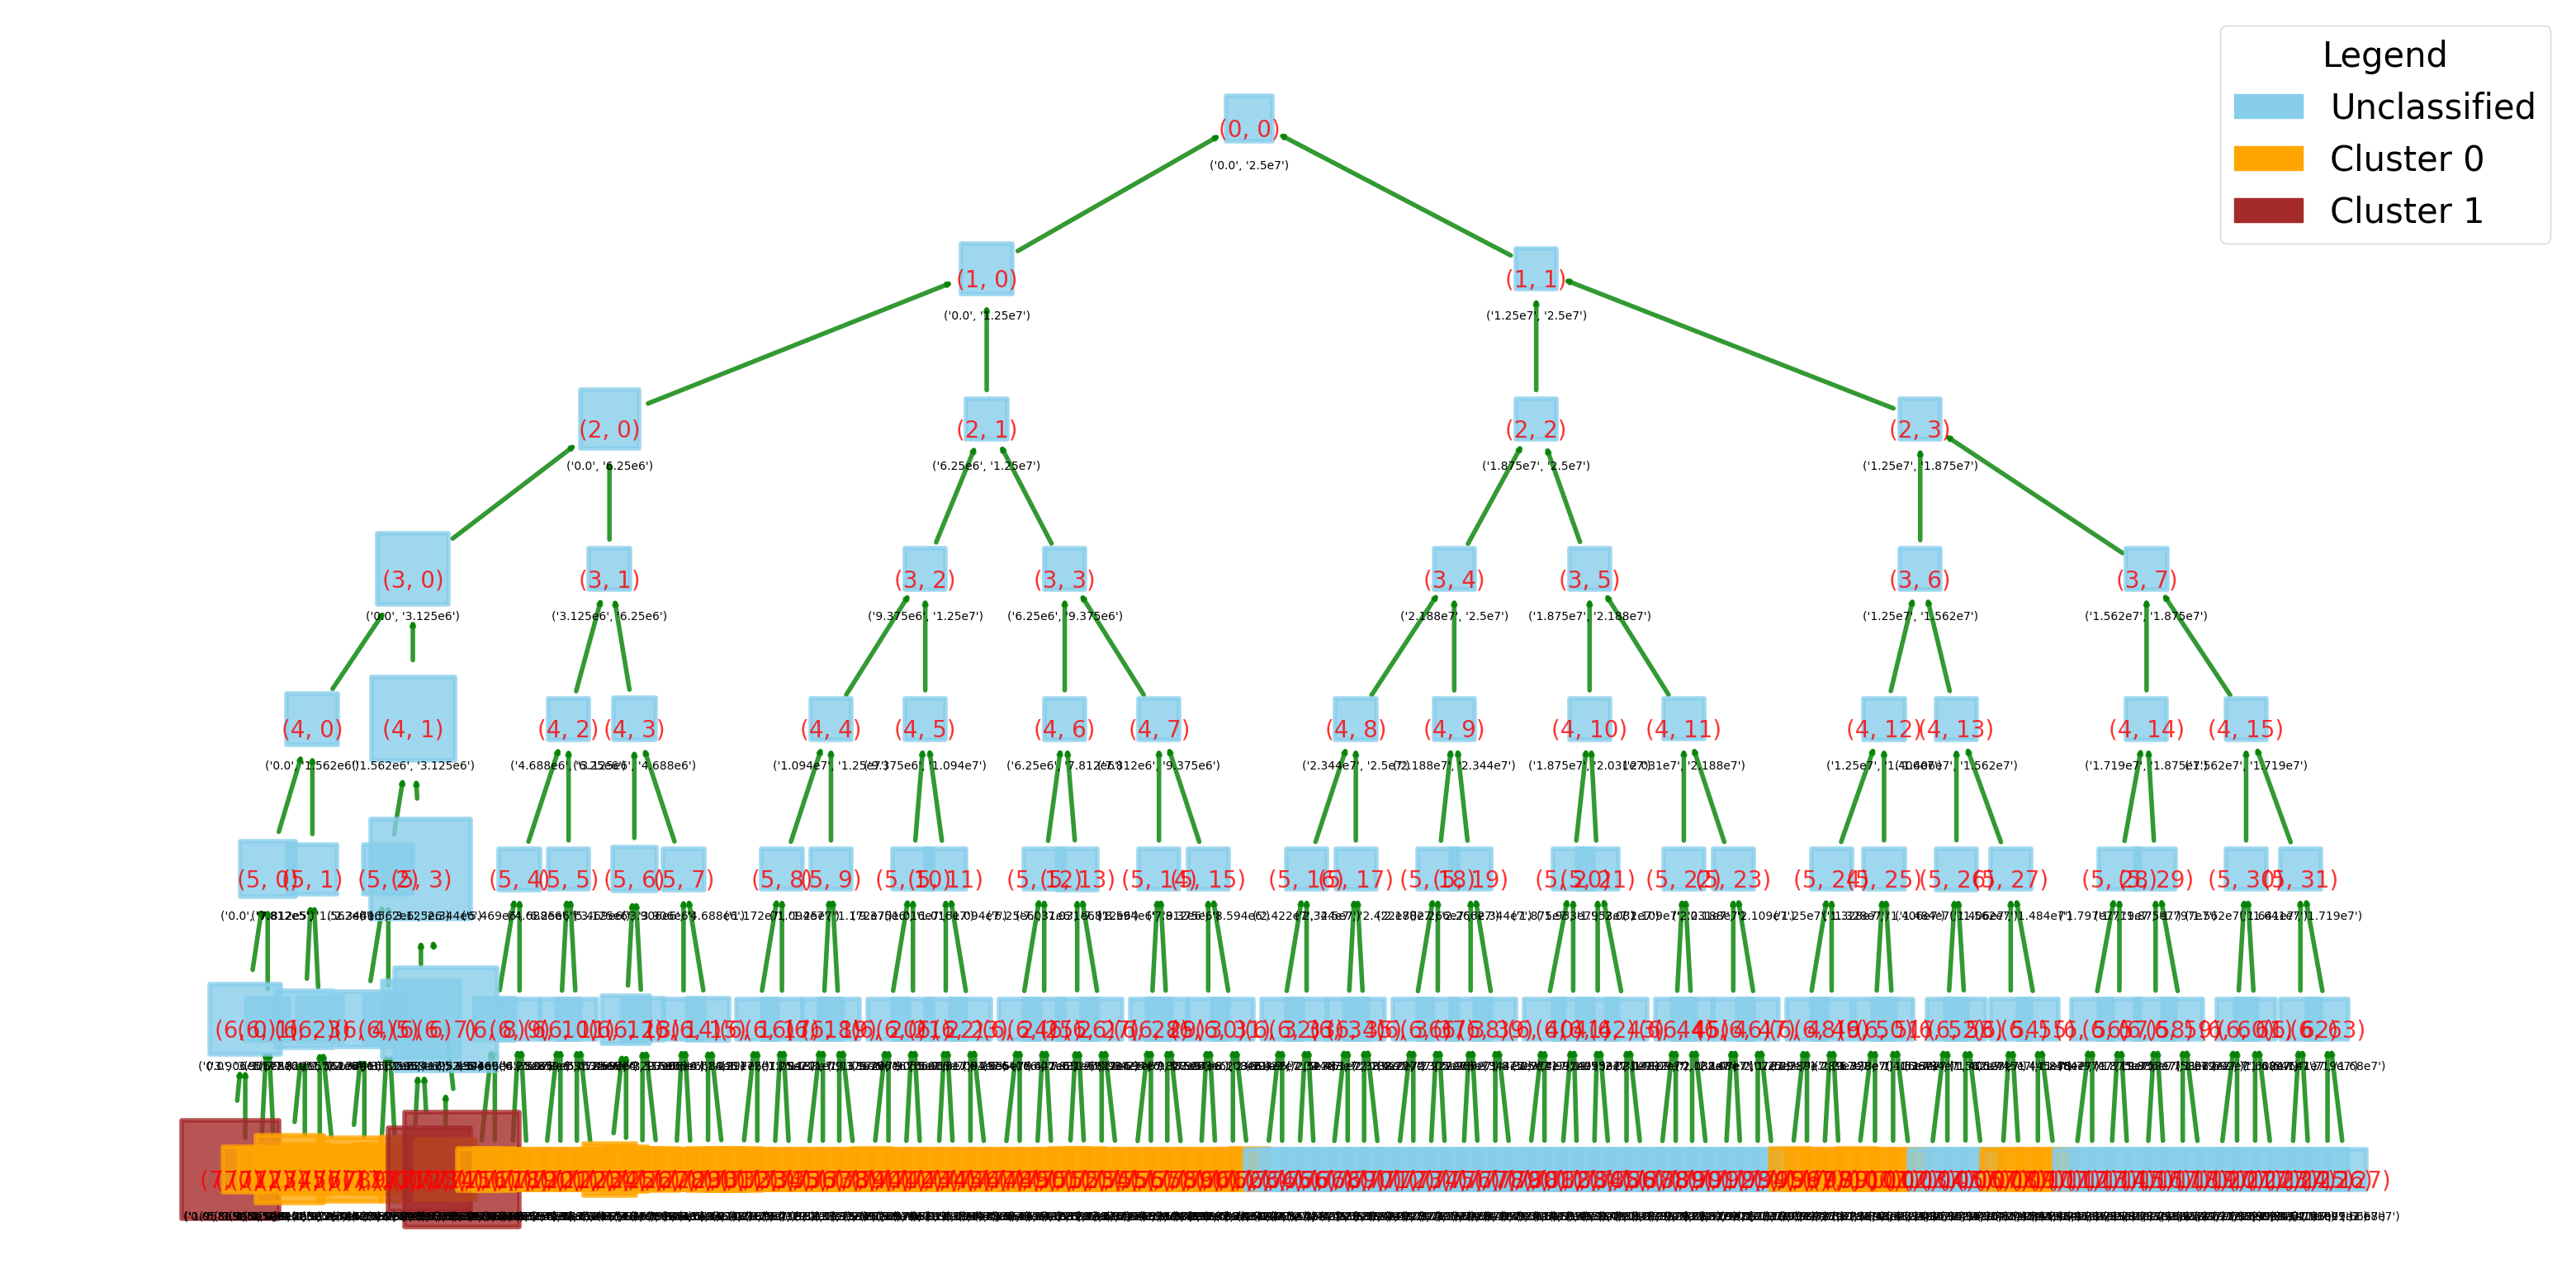

In [ ]:
tr_obj.calc_frequencies(sampling_rate)
tr_obj.plot_tree(node_size="average energy", node_colour=list(labels), freq_threshold=freq_threshold)

In [ ]:
# Set clusters to None to plot all of them, otherwise, plot a list of int
fig = plot.plot_fft_by_group(
    tr_obj, labels, no_clusters, sampling_rate,
    clusters=None, xlim=10, fundamental_freq=frequency,
    freq_threshold=freq_threshold
)

fig = plot.plot_reconstructions_by_group(tr_obj, labels, no_clusters, t_plot, freq_threshold)

pca results

In [ ]:
# plot pca results
# plot.plot_reconstructions_by_group(tr_obj, labels_pca, no_clusters, t_plot, sampling_rate)

separately plot reconstructions of all nodes belonging to selected clusters

In [ ]:
import wavelet_transform.wpt.inverse_transform as inv
# Add number to list to plot reconstructions of all nodes belonging to the cluster

plot_centres = []
for i, (node, assignment) in enumerate(zip(tr_obj.get_leaf_nodes(freq_threshold=freq_threshold), labels)):
    freq /= frequency
    if assignment in plot_centres:
        print("spectral entropy:", node.spectral_entropy)
        print("crest factor", node.crest_factor)
        rec = inv.inv_dwpt(tr_obj, node.level, nodes=node)
        fft_rec, freq = fft(rec, sampling_rate, frequency)
        plt.plot(freq, np.log10(np.abs(fft_rec)))
        plt.xlim(0, 5)
        plt.title(f"frequency range: {node.frequency_range}, fft")
        plt.show()
        plt.plot(rec)
        plt.title(f"reconstructed signal")
        plt.show()
